# Comparing different perturbation implementations

In this notebook, we run a simple comparison of the different
implementations of cosmological perturbations,
- Eiseinstein-Hu,
- CosmoPower-JAX,
- Bacco emulator.

We use each backend to compute the linear matter power spectrum $P_{\rm lin}(k)$
and the non-linear $P_{\rm nlin}(k)$ (excluding Eiseinstein-Hu).

For each case, we compare the outputs with `camb`.

## How to run the notebook

Run

```bash
uv sync --group notebooks
```

to install the necessary dependencies and the IPython kernel. Then you can just open the
notebook in VSCode with its Jupyter extension.

In [ ]:
from dataclasses import replace

import camb
import jax
import matplotlib.pyplot as plt
import numpy as np

from cosmograd import EisensteinHu, FlatLCDM
from cosmograd.perturbations.baccoemu import BaccoEmu
from cosmograd.perturbations.cosmopower import CosmoPower

%config InlineBackend.figure_format = 'retina'
jax.config.update("jax_enable_x64", True)

## Configuration and cosmological conventions
All editable settings are in this second code cell. Density parameters are
dimensionless present-day fractions, not physical densities Omega h^2.
We assume flat LambdaCDM with massless neutrinos, T_CMB = 2.7255 K,
N_eff = 3.044, and primordial pivot k_* = 0.05 Mpc^-1.
All spectra use k in Mpc^-1 and P in Mpc^3.

A_s = exp(ln10as) / 10^10 is shared by every backend. In this massless case
Omega_cb = Omega_m and total matter equals CDM plus baryons. Bacco derives its
own sigma8 from A_s; we never rescale the predictions to a common sigma8.

In [ ]:
# Shared cosmology. Radiation and pivot settings must match emulator conventions.
H0 = 67.4  # km/s/Mpc
omega_m = 0.315
omega_b = 0.0493
n_s = 0.965
ln10as = 3.044
z = 0.0
t_cmb, n_eff, k_pivot = 2.7255, 3.044, 0.05
# This comparison assumes flat LambdaCDM with massless neutrinos.
omega_k, neutrino_mass, num_massive_neutrinos = 0.0, 0.0, 0
w0, wa = -1.0, 0.0

# Evaluation grid, nonlinear prescriptions and CAMB transfer sampling.
k_min, k_max, n_k = 1e-3, 3.0, 300  # Mpc^-1
c_min, eta_0 = 3.13, 0.603
bacco_model = "Angulo2021"
halofit_version = "takahashi"
camb_transfer_settings = {"kmax": 10.0, "k_per_logint": 50}
camb_output_units = {"hubble_units": False, "k_hunit": False}  # Physical Mpc units.
camb_want_cls = False  # Only matter transfer functions are needed.

# Figure appearance.
figure_size, panel_ratios = (9, 7), [3, 1.4]
figure_layout = "constrained"
grid_alpha = 0.2
zero_line_style = {"color": "0.5", "linewidth": 0.8}

In [ ]:
# Derive physical densities for CAMB and the primordial amplitude for Bacco.
h = H0 / 100.0
ombh2 = omega_b * h**2
omch2 = (omega_m - omega_b) * h**2
A_s = np.exp(ln10as) * 1e-10
k = np.geomspace(k_min, k_max, n_k)  # Mpc^-1
print(f"h={h}, ombh2={ombh2:.7f}, omch2={omch2:.7f}, A_s={A_s:.7g}")

h=0.674, ombh2=0.0223958, omch2=0.1207011, A_s=2.098903e-09


## Backend construction

In [ ]:
background = FlatLCDM(H0=H0, omega_m=omega_m, t_cmb=t_cmb, n_eff=n_eff)
eh = EisensteinHu(background, omega_b=omega_b, n_s=n_s, ln10as=ln10as)
cp_linear = CosmoPower(background, omega_b=omega_b, n_s=n_s, ln10as=ln10as)
cp_nonlinear = replace(cp_linear, nonlinear=True, c_min=c_min, eta_0=eta_0)
bacco_linear = BaccoEmu(
    h=h,
    omega_cold=omega_m,
    omega_baryon=omega_b,
    ns=n_s,
    A_s=A_s,
    neutrino_mass=neutrino_mass,
    w0=w0,
    wa=wa,
    model_name=bacco_model,
)
bacco_nonlinear = replace(bacco_linear, nonlinear=True)
bacco_linear.check_bounds(k, z)
bacco_nonlinear.check_bounds(k, z)

Bacco linear and nonlinear training bounds passed.


## CAMB reference

CAMB settings:
- Physical CDM and baryon densities from the same inputs as above
- zero curvature
- massless neutrinos
- Select Takahashi Halofit for non-linear prescription

In [ ]:
pars = camb.CAMBparams()
pars.set_cosmology(
    H0=H0,
    ombh2=ombh2,
    omch2=omch2,
    omk=omega_k,
    mnu=neutrino_mass,
    num_massive_neutrinos=num_massive_neutrinos,
    nnu=n_eff,
    TCMB=t_cmb,
)
pars.set_dark_energy(w=w0, wa=wa)
pars.InitPower.set_params(As=A_s, ns=n_s, pivot_scalar=k_pivot)
pars.WantCls = camb_want_cls
pars.set_matter_power(redshifts=[z], **camb_transfer_settings)
pars.NonLinear = camb.model.NonLinear_both
pars.NonLinearModel.set_params(halofit_version=halofit_version)
results = camb.get_results(pars)

In [ ]:
camb_linear = results.get_matter_power_interpolator(
    nonlinear=False, **camb_output_units
).P(z, k)
camb_nonlinear = results.get_matter_power_interpolator(
    nonlinear=True, **camb_output_units
).P(z, k)

## Linear comparison
The reference is linear CAMB. Eisenstein-Hu is an analytic linear transfer
approximation with scale-independent growth; it cannot predict nonlinear power.
CosmoPower and Bacco emulate Boltzmann-solver spectra.

In [ ]:
linear_spectra = {
    "Eisenstein-Hu": np.asarray(eh.matter_power_spectrum(k, z)),
    "CosmoPower (linear)": np.asarray(cp_linear.matter_power_spectrum(k, z)),
    "BaccoEmu (linear)": np.asarray(bacco_linear.matter_power_spectrum(k, z)),
    "CAMB (linear)": np.asarray(camb_linear),
}

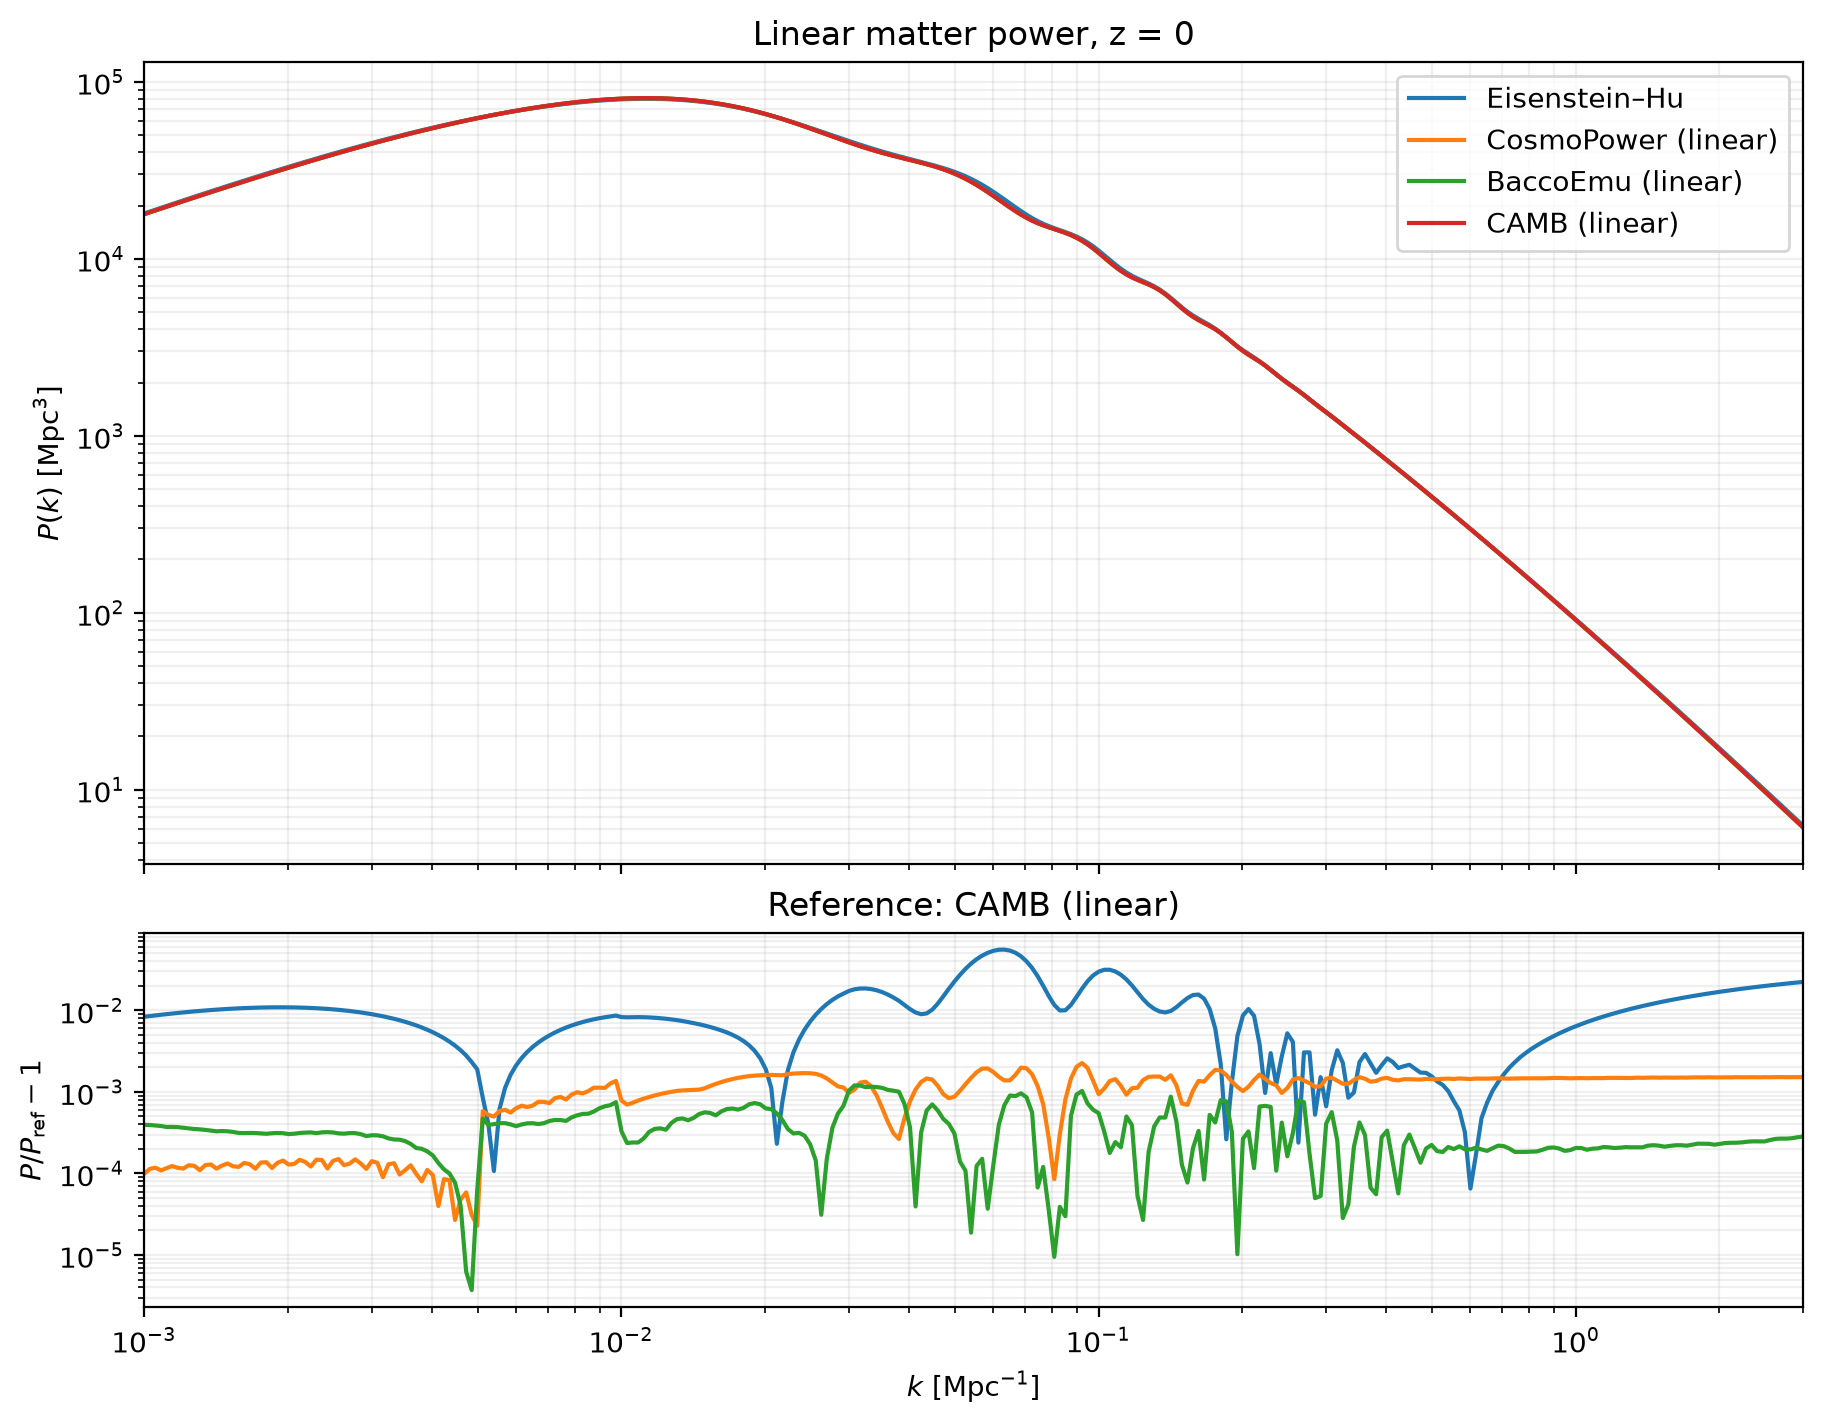

In [ ]:
def plot_comparison(
    spectra: dict[str, np.ndarray], reference: np.ndarray, title: str, denominator: str
) -> plt.Figure:
    """Plot physical power and percent residuals, checking numerical validity."""
    fig, (ax, residual_ax) = plt.subplots(
        2,
        1,
        sharex=True,
        figsize=figure_size,
        gridspec_kw={"height_ratios": panel_ratios},
        layout=figure_layout,
    )
    assert reference.shape == k.shape
    assert np.all(np.isfinite(reference) & (reference > 0))
    eps = np.finfo(float).eps
    for label, power in spectra.items():
        assert power.shape == k.shape, label
        assert np.all(np.isfinite(power) & (power > 0)), label
        residual = power / reference - 1.0
        assert np.all(np.isfinite(residual)), label
        (line,) = ax.loglog(k, np.abs(power + eps), label=label)
        if label == denominator:
            continue
        residual_ax.loglog(
            np.abs(k + eps),
            np.abs(residual + eps),
            color=line.get_color(),
            linestyle=line.get_linestyle(),
        )
    ax.set(title=f"{title}, z = {z:g}", ylabel=r"$P(k)\ [\mathrm{Mpc}^3]$")
    ax.legend()
    residual_ax.set(
        xlabel=r"$k\ [\mathrm{Mpc}^{-1}]$",
        ylabel=r"$P/P_{\rm ref}-1$",
        title=f"Reference: {denominator}",
        xlim=(k[0], k[-1]),
    )
    for axis in (ax, residual_ax):
        axis.grid(True, which="both", alpha=grid_alpha)
    return fig


linear_figure = plot_comparison(
    linear_spectra, camb_linear, "Linear matter power", "CAMB (linear)"
)
plt.show()

## Nonlinear comparison

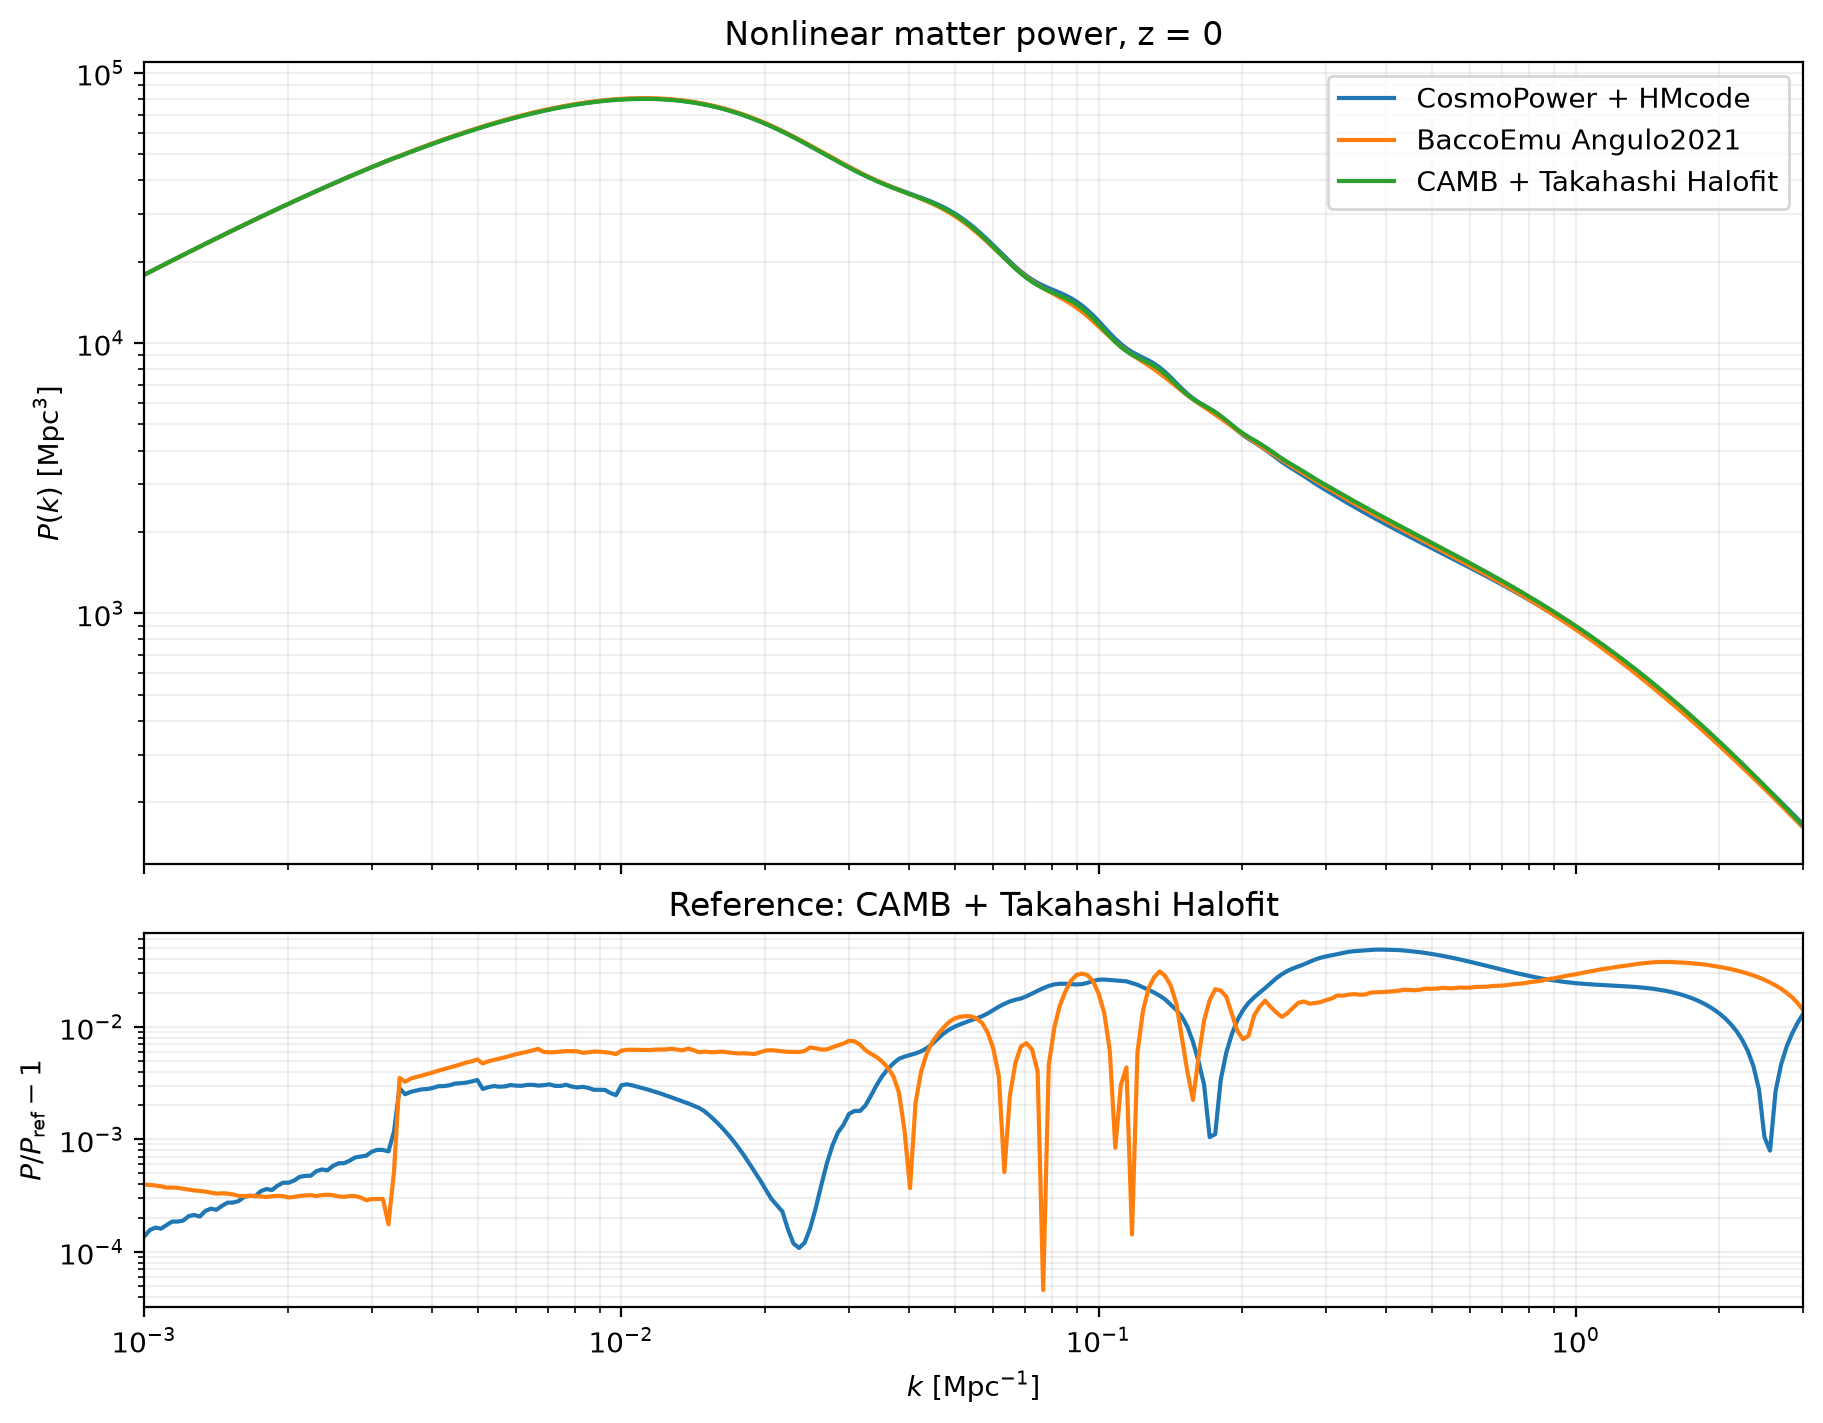

In [ ]:
nonlinear_spectra = {
    "CosmoPower + HMcode": np.asarray(cp_nonlinear.matter_power_spectrum(k, z)),
    f"BaccoEmu {bacco_model}": np.asarray(bacco_nonlinear.matter_power_spectrum(k, z)),
    f"CAMB + {halofit_version.title()} Halofit": np.asarray(camb_nonlinear),
}
nonlinear_figure = plot_comparison(
    nonlinear_spectra,
    camb_nonlinear,
    "Nonlinear matter power",
    f"CAMB + {halofit_version.title()} Halofit",
)
plt.show()

## References

- [Eisenstein & Hu (1998)](https://arxiv.org/abs/astro-ph/9709112): analytic
  linear transfer function with baryon acoustic features.
- [CosmoPower-JAX documentation](https://github.com/dpiras/cosmopower-jax) and
  [CosmoPower (2022)](https://arxiv.org/abs/2106.03846): trained emulators.
- [Bacco documentation](https://baccoemu.readthedocs.io/en/latest/): linear,
  nonlinear and separate baryonic-feedback emulators and training conventions.
- [CAMB power interpolation and unit flags](https://camb.readthedocs.io/en/latest/results.html#camb.results.CAMBdata.get_matter_power_interpolator).
- [CAMB nonlinear model selection](https://camb.readthedocs.io/en/latest/nonlinear.html)
  and [Takahashi et al. (2012)](https://arxiv.org/abs/1208.2701): Halofit reference.